# E-Commerce Customer Segmentation using RFM and K-Means Clustering

## Project Overview

This project performs customer segmentation using the RFM (Recency, Frequency, Monetary) analysis and K-Means clustering algorithm.

The main objectives are:

- Clean and preprocess e-commerce transaction data
- Calculate customer-level RFM metrics
- Transform and standardize RFM features
- Determine the appropriate number of clusters using the Elbow Method and Silhouette Score
- Apply K-Means clustering
- Create meaningful customer personas
- Develop marketing strategies for each customer segment
- Visualize and analyze the customer segments

In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

import warnings
warnings.filterwarnings('ignore')

print("Libraries imported successfully!")

Libraries imported successfully!


In [11]:
# Load the original Online Retail dataset

file_path = "../data/Online Retail.xlsx"

df = pd.read_excel(file_path)

print("Dataset loaded successfully!")
print("Shape:", df.shape)

Dataset loaded successfully!
Shape: (541909, 8)


In [12]:
# Display basic information about the dataset

print("Dataset Shape:", df.shape)
print("\nColumn Names:")
print(df.columns.tolist())

print("\nFirst 5 Rows:")
display(df.head())

Dataset Shape: (541909, 8)

Column Names:
['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']

First 5 Rows:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [13]:
# Check data types and missing values

print("Data Types:")
print(df.dtypes)

print("\nMissing Values:")
print(df.isnull().sum())

Data Types:
InvoiceNo              object
StockCode              object
Description            object
Quantity                int64
InvoiceDate    datetime64[us]
UnitPrice             float64
CustomerID            float64
Country                   str
dtype: object

Missing Values:
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64


In [14]:
# Remove transactions without CustomerID
df = df.dropna(subset=['CustomerID'])

# Remove cancelled transactions
df = df[~df['InvoiceNo'].astype(str).str.startswith('C')]

# Keep only positive quantities and prices
df = df[(df['Quantity'] > 0) & (df['UnitPrice'] > 0)]

print("Cleaned Dataset Shape:", df.shape)

Cleaned Dataset Shape: (397884, 8)


In [15]:
# Calculate the total amount for each transaction

df['TotalAmount'] = df['Quantity'] * df['UnitPrice']

print("TotalAmount feature created successfully!")
display(df[['Quantity', 'UnitPrice', 'TotalAmount']].head())

TotalAmount feature created successfully!


,Quantity,UnitPrice,TotalAmount
0,6,2.55,15.30
1,6,3.39,20.34
2,8,2.75,22.00
3,6,3.39,20.34
4,6,3.39,20.34


In [16]:
# Convert InvoiceDate to datetime
df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'])

# Set the reference date as one day after the last transaction
reference_date = df['InvoiceDate'].max() + pd.Timedelta(days=1)

# Calculate RFM metrics for each customer
rfm = df.groupby('CustomerID').agg(
    Recency=('InvoiceDate', lambda x: (reference_date - x.max()).days),
    Frequency=('InvoiceNo', 'nunique'),
    Monetary=('TotalAmount', 'sum')
).reset_index()

print("RFM Analysis Completed!")
print("Number of Customers:", len(rfm))

display(rfm.head())

RFM Analysis Completed!
Number of Customers: 4338


,CustomerID,Recency,Frequency,Monetary
0,12346.0,326,1,77183.60
1,12347.0,2,7,4310.00
2,12348.0,75,4,1797.24
3,12349.0,19,1,1757.55
4,12350.0,310,1,334.40


In [17]:
# Display descriptive statistics for RFM metrics

rfm_stats = rfm[['Recency', 'Frequency', 'Monetary']].describe()

display(rfm_stats.round(2))

,Recency,Frequency,Monetary
count,4338.00,4338.00,4338.00
mean,92.54,4.27,2054.27
std,100.01,7.70,8989.23
min,1.00,1.00,3.75
25%,18.00,1.00,307.41
50%,51.00,2.00,674.48
75%,142.00,5.00,1661.74
max,374.00,209.00,280206.02


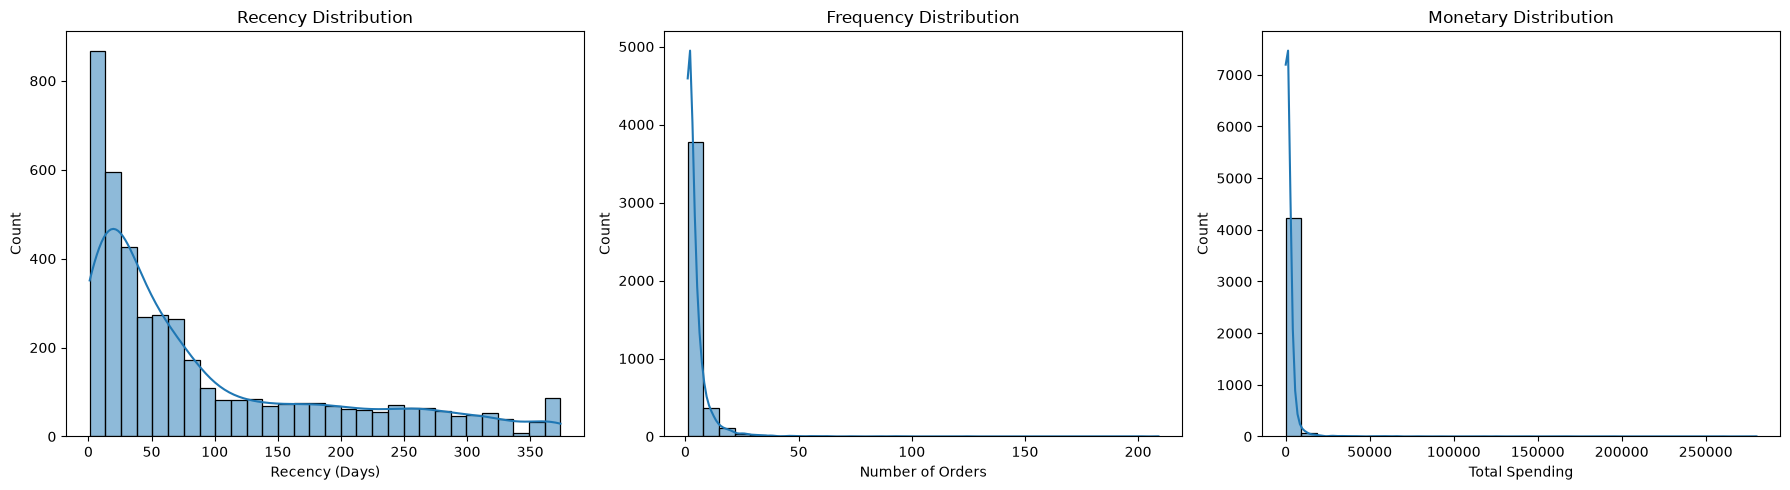

In [18]:
# Visualize the distribution of RFM metrics

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.histplot(rfm['Recency'], bins=30, kde=True, ax=axes[0])
axes[0].set_title('Recency Distribution')
axes[0].set_xlabel('Recency (Days)')

sns.histplot(rfm['Frequency'], bins=30, kde=True, ax=axes[1])
axes[1].set_title('Frequency Distribution')
axes[1].set_xlabel('Number of Orders')

sns.histplot(rfm['Monetary'], bins=30, kde=True, ax=axes[2])
axes[2].set_title('Monetary Distribution')
axes[2].set_xlabel('Total Spending')

plt.tight_layout()
plt.show()

In [19]:
# Select RFM features
features = ['Recency', 'Frequency', 'Monetary']

# Apply log transformation
rfm_log = np.log1p(rfm[features])

# Standardize the transformed features
scaler = StandardScaler()
rfm_scaled = scaler.fit_transform(rfm_log)

# Convert to DataFrame
rfm_scaled_df = pd.DataFrame(
    rfm_scaled,
    columns=features
)

# Add CustomerID
rfm_scaled_df.insert(0, 'CustomerID', rfm['CustomerID'].values)

print("RFM transformation and standardization completed!")

display(rfm_scaled_df.head())

RFM transformation and standardization completed!


,CustomerID,Recency,Frequency,Monetary
0,12346.0,1.461993,-0.955214,3.706225
1,12347.0,-2.038734,1.074425,1.411843
2,12348.0,0.373104,0.386304,0.716489
3,12349.0,-0.623086,-0.955214,0.698739
4,12350.0,1.424558,-0.955214,-0.618962


In [20]:
# Prepare data for clustering
X = rfm_scaled_df[features]

# Test different numbers of clusters
k_values = range(2, 11)

inertias = []
silhouette_scores = []

for k in k_values:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    
    labels = kmeans.fit_predict(X)
    
    inertias.append(kmeans.inertia_)
    silhouette_scores.append(silhouette_score(X, labels))

# Display results
results = pd.DataFrame({
    'K': list(k_values),
    'Inertia': inertias,
    'Silhouette Score': silhouette_scores
})

display(results.round(4))

,K,Inertia,Silhouette Score
0,2,6481.2253,0.4329
1,3,4867.8466,0.3365
2,4,3938.5100,0.3371
3,5,3295.9763,0.3161
4,6,2855.0112,0.3133
5,7,2548.9143,0.3100
6,8,2336.7775,0.3008
7,9,2155.6482,0.2817
8,10,1999.9033,0.2787


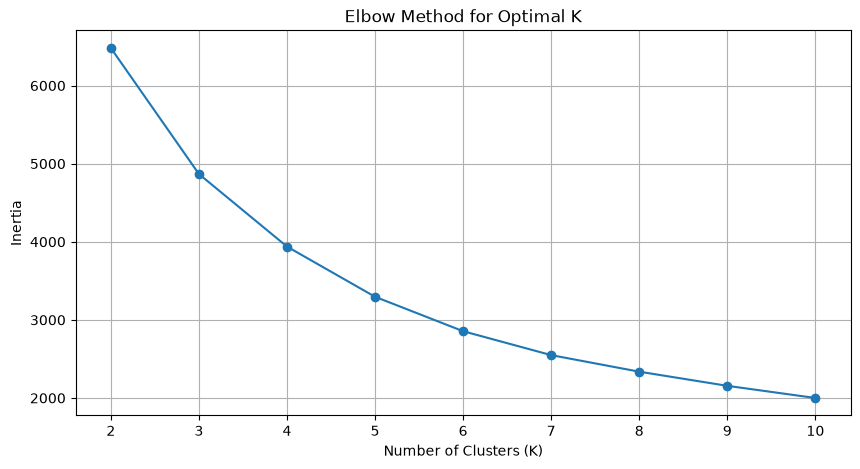

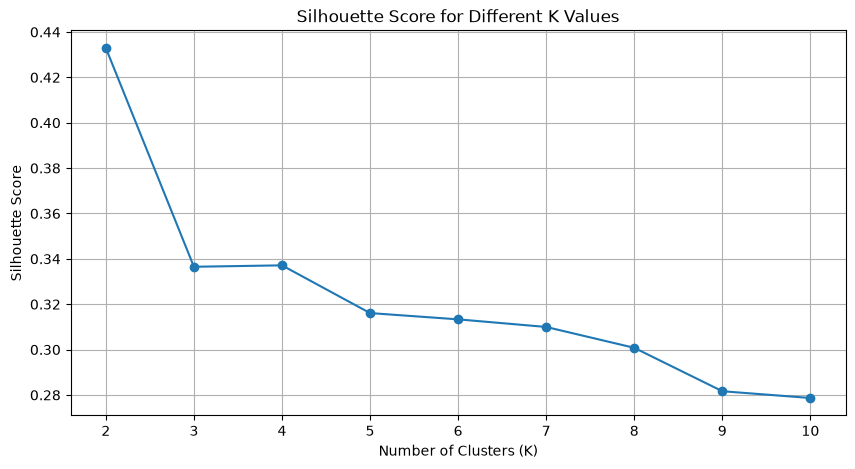

In [21]:
# Visualize the Elbow Method

plt.figure(figsize=(10, 5))

plt.plot(
    results['K'],
    results['Inertia'],
    marker='o'
)

plt.xlabel('Number of Clusters (K)')
plt.ylabel('Inertia')
plt.title('Elbow Method for Optimal K')
plt.xticks(results['K'])
plt.grid(True)
plt.show()


# Visualize Silhouette Scores

plt.figure(figsize=(10, 5))

plt.plot(
    results['K'],
    results['Silhouette Score'],
    marker='o'
)

plt.xlabel('Number of Clusters (K)')
plt.ylabel('Silhouette Score')
plt.title('Silhouette Score for Different K Values')
plt.xticks(results['K'])
plt.grid(True)
plt.show()

In [22]:
# Apply K-Means clustering with K = 4

kmeans_final = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

rfm_scaled_df['Cluster'] = kmeans_final.fit_predict(X)

print("K-Means clustering completed!")
print("\nCustomers in each cluster:")

display(
    rfm_scaled_df['Cluster']
    .value_counts()
    .sort_index()
)

K-Means clustering completed!

Customers in each cluster:


Cluster
0     837
1     716
2    1173
3    1612
Name: count, dtype: int64

In [23]:
# Combine original RFM values with cluster labels

rfm_clustered = rfm.merge(
    rfm_scaled_df[['CustomerID', 'Cluster']],
    on='CustomerID'
)

# Calculate average RFM values for each cluster
cluster_profile = rfm_clustered.groupby('Cluster').agg(
    Customers=('CustomerID', 'count'),
    Avg_Recency=('Recency', 'mean'),
    Avg_Frequency=('Frequency', 'mean'),
    Avg_Monetary=('Monetary', 'mean')
).round(2)

print("Customer Cluster Profile:")
display(cluster_profile)

Customer Cluster Profile:


,Customers,Avg_Recency,Avg_Frequency,Avg_Monetary
Cluster,,,,
0,837,18.12,2.15,551.82
1,716,12.13,13.71,8074.27
2,1173,71.08,4.08,1802.83
3,1612,182.50,1.32,343.45


In [24]:
# Assign meaningful customer personas to each cluster

persona_names = {
    0: 'New / Potential Customers',
    1: 'VIP / Loyal Customers',
    2: 'Regular Customers',
    3: 'At-Risk / Lost Customers'
}

marketing_strategies = {
    0: 'Welcome offers, second-purchase discounts, and product recommendations',
    1: 'VIP rewards, exclusive offers, loyalty benefits, and early access',
    2: 'Cross-selling, personalized recommendations, and loyalty incentives',
    3: 'Win-back campaigns, personalized discounts, and re-engagement emails'
}

rfm_clustered['Persona'] = rfm_clustered['Cluster'].map(persona_names)

rfm_clustered['MarketingStrategy'] = (
    rfm_clustered['Cluster'].map(marketing_strategies)
)

print("Customer personas assigned successfully!")

display(
    rfm_clustered[
        [
            'CustomerID',
            'Recency',
            'Frequency',
            'Monetary',
            'Cluster',
            'Persona',
            'MarketingStrategy'
        ]
    ].head(10)
)

Customer personas assigned successfully!


,CustomerID,Recency,Frequency,Monetary,Cluster,Persona,MarketingStrategy
0,12346.0,326,1,77183.60,2,Regular Customers,"Cross-selling, personalized recommendations, a..."
1,12347.0,2,7,4310.00,1,VIP / Loyal Customers,"VIP rewards, exclusive offers, loyalty benefit..."
2,12348.0,75,4,1797.24,2,Regular Customers,"Cross-selling, personalized recommendations, a..."
3,12349.0,19,1,1757.55,0,New / Potential Customers,"Welcome offers, second-purchase discounts, and..."
4,12350.0,310,1,334.40,3,At-Risk / Lost Customers,"Win-back campaigns, personalized discounts, an..."
5,12352.0,36,8,2506.04,2,Regular Customers,"Cross-selling, personalized recommendations, a..."
6,12353.0,204,1,89.00,3,At-Risk / Lost Customers,"Win-back campaigns, personalized discounts, an..."
7,12354.0,232,1,1079.40,3,At-Risk / Lost Customers,"Win-back campaigns, personalized discounts, an..."
8,12355.0,214,1,459.40,3,At-Risk / Lost Customers,"Win-back campaigns, personalized discounts, an..."
9,12356.0,23,3,2811.43,2,Regular Customers,"Cross-selling, personalized recommendations, a..."


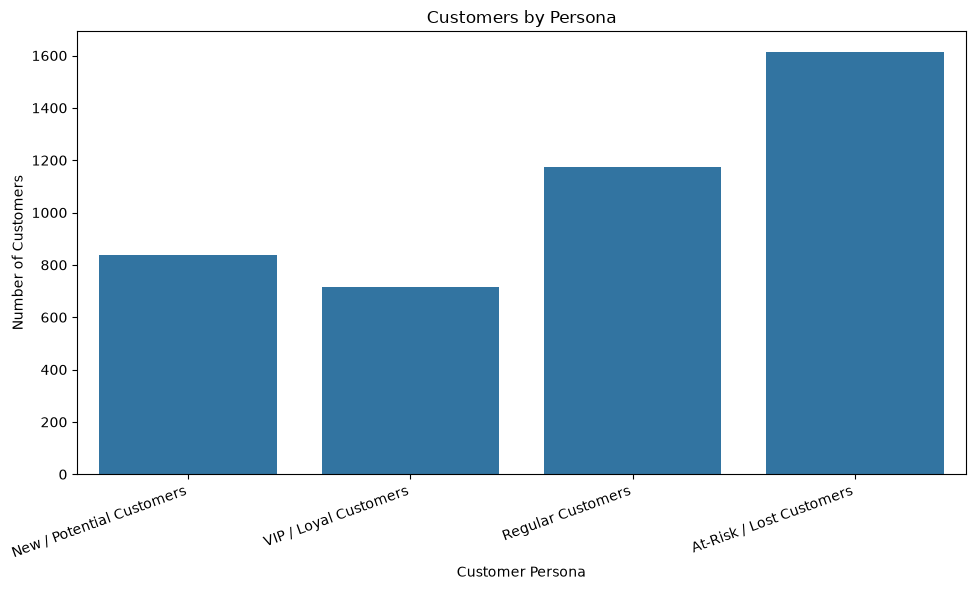

In [25]:
# Define the desired persona order

persona_order = [
    'New / Potential Customers',
    'VIP / Loyal Customers',
    'Regular Customers',
    'At-Risk / Lost Customers'
]

# Count customers in each persona
persona_counts = (
    rfm_clustered['Persona']
    .value_counts()
    .reindex(persona_order)
)

# Create the chart
plt.figure(figsize=(10, 6))

sns.barplot(
    x=persona_counts.index,
    y=persona_counts.values
)

plt.title('Customers by Persona')
plt.xlabel('Customer Persona')
plt.ylabel('Number of Customers')
plt.xticks(rotation=20, ha='right')

plt.tight_layout()
plt.show()

In [26]:
# Calculate average RFM values for each persona

persona_profile = (
    rfm_clustered
    .groupby('Persona')
    .agg(
        Customers=('CustomerID', 'count'),
        Avg_Recency=('Recency', 'mean'),
        Avg_Frequency=('Frequency', 'mean'),
        Avg_Monetary=('Monetary', 'mean')
    )
    .reindex(persona_order)
    .round(2)
)

print("Customer Persona Profile:")
display(persona_profile)

Customer Persona Profile:


,Customers,Avg_Recency,Avg_Frequency,Avg_Monetary
Persona,,,,
New / Potential Customers,837,18.12,2.15,551.82
VIP / Loyal Customers,716,12.13,13.71,8074.27
Regular Customers,1173,71.08,4.08,1802.83
At-Risk / Lost Customers,1612,182.50,1.32,343.45


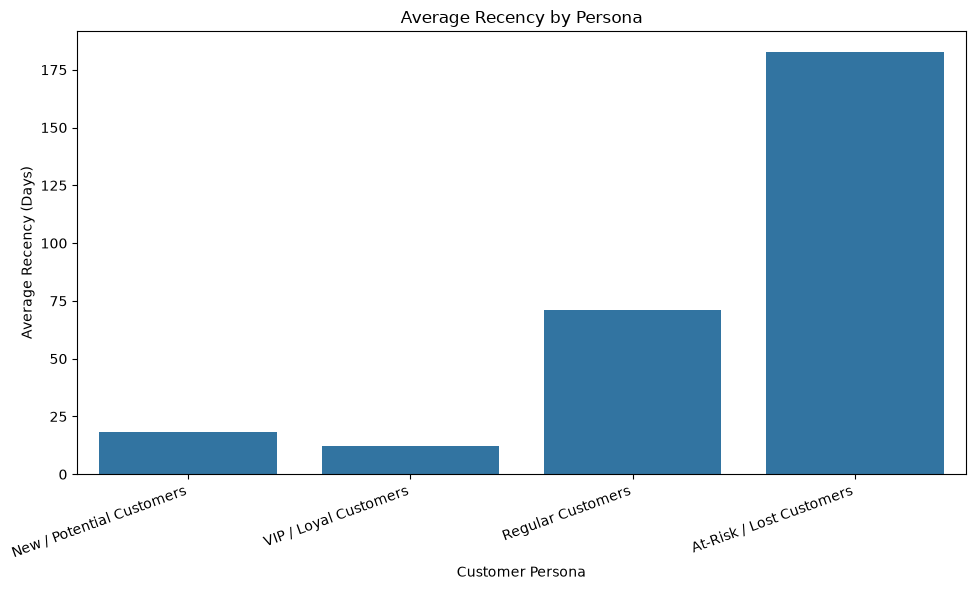

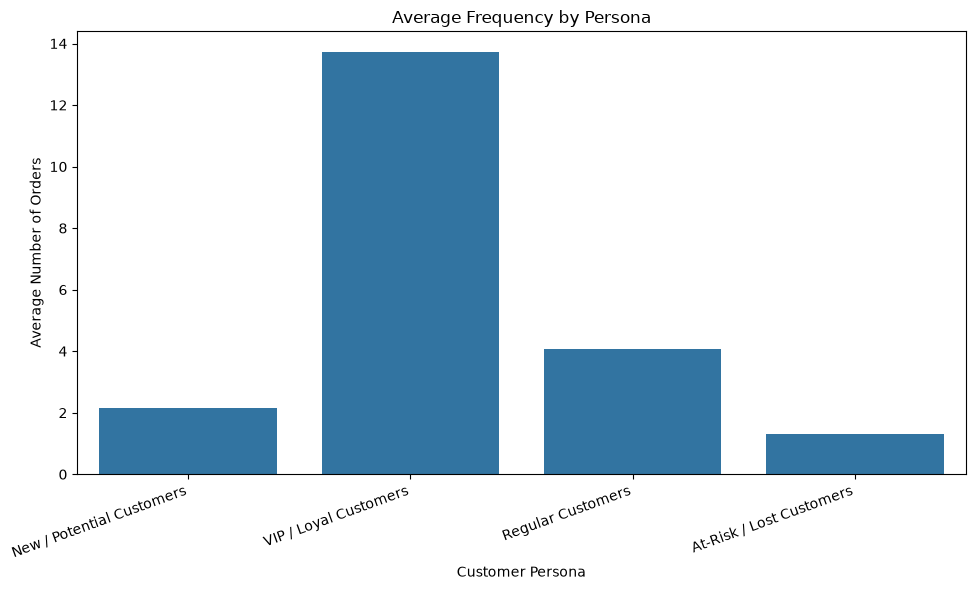

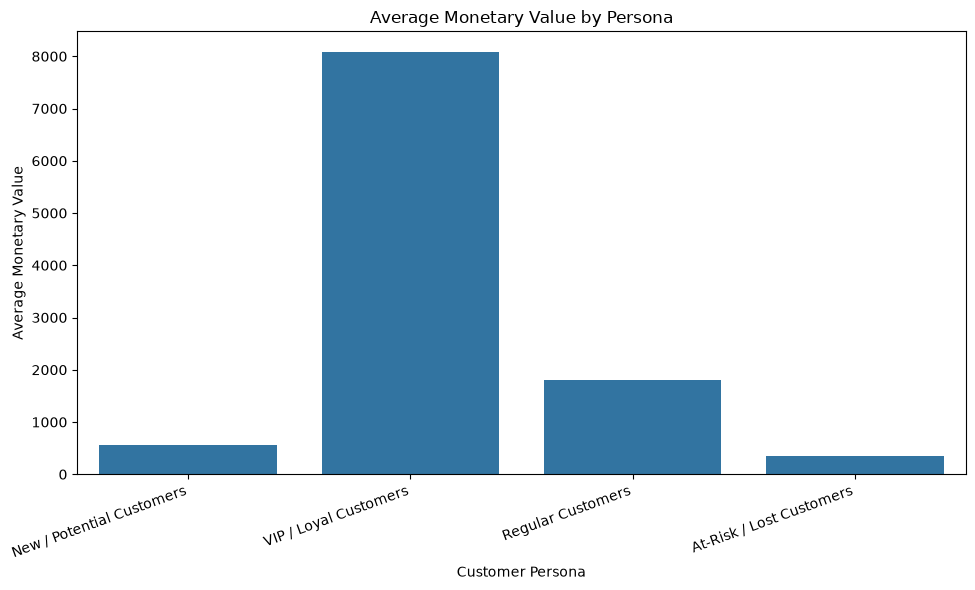

In [27]:
# Create RFM comparison charts

metrics = [
    ('Avg_Recency', 'Average Recency by Persona', 'Average Recency (Days)'),
    ('Avg_Frequency', 'Average Frequency by Persona', 'Average Number of Orders'),
    ('Avg_Monetary', 'Average Monetary Value by Persona', 'Average Monetary Value')
]

for metric, title, ylabel in metrics:
    
    plt.figure(figsize=(10, 6))
    
    sns.barplot(
        x=persona_profile.index,
        y=persona_profile[metric].values
    )
    
    plt.title(title)
    plt.xlabel('Customer Persona')
    plt.ylabel(ylabel)
    plt.xticks(rotation=20, ha='right')
    
    plt.tight_layout()
    plt.show()

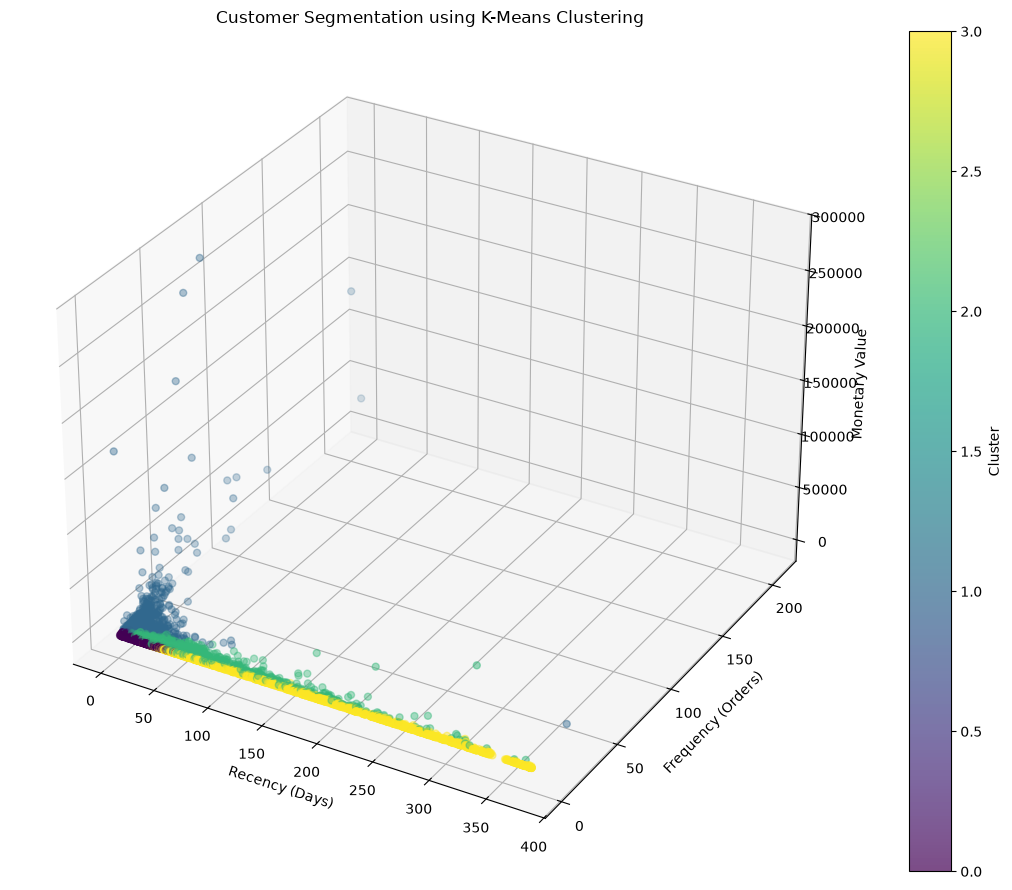

In [28]:
# 3D visualization of customer segments

from mpl_toolkits.mplot3d import Axes3D

fig = plt.figure(figsize=(12, 9))

ax = fig.add_subplot(111, projection='3d')

scatter = ax.scatter(
    rfm_clustered['Recency'],
    rfm_clustered['Frequency'],
    rfm_clustered['Monetary'],
    c=rfm_clustered['Cluster'],
    cmap='viridis',
    s=25,
    alpha=0.7
)

ax.set_xlabel('Recency (Days)')
ax.set_ylabel('Frequency (Orders)')
ax.set_zlabel('Monetary Value')

ax.set_title('Customer Segmentation using K-Means Clustering')

fig.colorbar(
    scatter,
    ax=ax,
    label='Cluster'
)

plt.tight_layout()
plt.show()

In [29]:
# Save the final customer segmentation results

output_file = "../data/final_customer_segments.csv"

rfm_clustered.to_csv(output_file, index=False)

print("Final segmentation saved successfully!")
print(f"File: {output_file}")
print(f"Total customers: {len(rfm_clustered)}")

Final segmentation saved successfully!
File: ../data/final_customer_segments.csv
Total customers: 4338


# Conclusion

This project successfully segmented e-commerce customers using RFM (Recency, Frequency, Monetary) analysis and K-Means clustering.

The original Online Retail dataset contained 541,909 transactions. After removing records without Customer IDs, cancelled transactions, and invalid quantities or prices, 397,884 valid transactions remained. These transactions were used to calculate RFM metrics for 4,338 customers.

Because the RFM variables had different scales and skewed distributions, log transformation and standardization were applied before clustering. The Elbow Method and Silhouette Score were used to evaluate different numbers of clusters. Although K=2 achieved the highest Silhouette Score, K=4 was selected because it provided more useful and actionable customer segments for marketing purposes.

The four resulting customer personas were:

- **VIP / Loyal Customers:** Recent, frequent, and high-value customers who should receive loyalty rewards, exclusive offers, and early access.
- **New / Potential Customers:** Recent customers with relatively few purchases who can be encouraged through welcome offers and second-purchase discounts.
- **Regular Customers:** Customers with moderate purchasing activity who can be targeted through cross-selling and personalized recommendations.
- **At-Risk / Lost Customers:** Customers with long periods since their last purchase and low purchasing activity who can be targeted through win-back and re-engagement campaigns.

Overall, the segmentation demonstrates how RFM analysis and machine learning can transform raw transaction data into actionable customer insights. These segments can help businesses develop more targeted marketing strategies, improve customer retention, and prioritize high-value customers.

In [30]:
# Final validation of the customer segmentation results

print("===== FINAL PROJECT VALIDATION =====")

print(f"Total customers: {len(rfm_clustered)}")
print(f"Missing Customer IDs: {rfm_clustered['CustomerID'].isnull().sum()}")
print(f"Missing Personas: {rfm_clustered['Persona'].isnull().sum()}")
print(f"Number of Clusters: {rfm_clustered['Cluster'].nunique()}")

print("\nCustomers per Persona:")
display(
    rfm_clustered['Persona']
    .value_counts()
    .reindex(persona_order)
)

print("\nFinal RFM Summary:")
display(
    rfm_clustered[
        ['Recency', 'Frequency', 'Monetary']
    ].describe().round(2)
)

print("\n✓ Validation completed successfully!")

===== FINAL PROJECT VALIDATION =====
Total customers: 4338
Missing Customer IDs: 0
Missing Personas: 0
Number of Clusters: 4

Customers per Persona:


Persona
New / Potential Customers     837
VIP / Loyal Customers         716
Regular Customers            1173
At-Risk / Lost Customers     1612
Name: count, dtype: int64


Final RFM Summary:


,Recency,Frequency,Monetary
count,4338.00,4338.00,4338.00
mean,92.54,4.27,2054.27
std,100.01,7.70,8989.23
min,1.00,1.00,3.75
25%,18.00,1.00,307.41
50%,51.00,2.00,674.48
75%,142.00,5.00,1661.74
max,374.00,209.00,280206.02



✓ Validation completed successfully!
